# 🤖 Artificial Intelligence & Machine Learning – Task 2
## Feature Engineering, Model Optimization & Performance Comparison

**Organization:** MainCraft Technology  
**Project:** Enhanced House Price Prediction System  
**Dataset:** California Housing Dataset  
**Author:** AI & ML Engineering Intern  

---

### Objectives & Professional Focus
In real-world machine learning engineering:
- Models are rarely deployed after the first attempt.
- Data must be cleaned, transformed, and properly standardized.
- Multiple algorithms with contrasting inductive biases are trained and systematically evaluated.
- Decisions are justified using measurable performance metrics (RMSE, $R^2$) and visual diagnostic validations.

### Deliverables Covered in this Notebook:
1. **Feature Engineering & Preprocessing:** Data standardization using `StandardScaler`.
2. **Multi-Model Training:** Linear Regression (baseline), Ridge Regression (regularized), and Decision Tree Regressor (non-linear).
3. **Structured Performance Evaluation:** Quantitative comparison table tracking Root Mean Squared Error (RMSE) and $R^2$ Score.
4. **Visual Diagnostic Validation:** Actual vs. Predicted plots, residual error distribution, and feature importance breakdown.
5. **Model Persistence:** Saving best model (`best_model.joblib`) and scaler (`scaler.joblib`) for production inference.


## Step 1: Import Required Libraries
We import essential packages for data manipulation, visualization, modeling, and evaluation:
- `pandas` & `numpy` for data manipulation and array computation
- `matplotlib.pyplot` & `seaborn` for visual diagnostics
- `sklearn.datasets` for retrieving California Housing data
- `sklearn.preprocessing.StandardScaler` for feature scaling
- `sklearn.model_selection.train_test_split` for train/test data splitting
- `sklearn.linear_model` (`LinearRegression`, `Ridge`) and `sklearn.tree` (`DecisionTreeRegressor`) for predictive modeling
- `sklearn.metrics` (`mean_squared_error`, `r2_score`) for empirical evaluation
- `joblib` for model serialization


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Set plotting styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10

print("All required libraries imported successfully!")

All required libraries imported successfully!


## Step 2: Load the Dataset & Exploratory Overview
The California Housing Dataset consists of 20,640 census block group observations with 8 continuous features:
- `MedInc`: Median income in block group (in tens of thousands of dollars)
- `HouseAge`: Median house age in block group
- `AveRooms`: Average number of rooms per household
- `AveBedrms`: Average number of bedrooms per household
- `Population`: Block group population
- `AveOccup`: Average number of household members
- `Latitude` & `Longitude`: Geographical coordinates
- **Target Variable (`HousePrice`):** Median house value in hundreds of thousands of dollars ($100,000s).


In [2]:
# Load California housing dataset as a pandas DataFrame
data = fetch_california_housing(as_frame=True)
df = pd.concat([data.data, data.target.rename("HousePrice")], axis=1)

print(f"Dataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")
print("\nMissing Values Check:")
print(df.isnull().sum())
df.head()

Dataset Dimensions: 20640 rows x 9 columns

Missing Values Check:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
HousePrice    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HousePrice
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Summary statistics of features and target
df.describe().T[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
MedInc,3.870671,1.899822,0.499900,3.534800,15.000100
HouseAge,28.639486,12.585558,1.000000,29.000000,52.000000
AveRooms,5.429000,2.474173,0.846154,5.229129,141.909091
AveBedrms,1.096675,0.473911,0.333333,1.048780,34.066667
Population,1425.476744,1132.462122,3.000000,1166.000000,35682.000000
AveOccup,3.070655,10.386050,0.692308,2.818116,1243.333333
Latitude,35.631861,2.135952,32.540000,34.260000,41.950000
Longitude,-119.569704,2.003532,-124.350000,-118.490000,-114.310000
HousePrice,2.068558,1.153956,0.149990,1.797000,5.000010


## Step 3: Separate Features and Target Variable
We split the tabular dataset into feature matrix ($X$) and target vector ($y$).


In [4]:
# Separate input features (X) and target variable (y)
X = df.drop("HousePrice", axis=1)
y = df["HousePrice"]

print(f"Feature matrix (X) shape: {X.shape}")
print(f"Target vector (y) shape:   {y.shape}")

Feature matrix (X) shape: (20640, 8)
Target vector (y) shape:   (20640,)


## Step 4: Feature Scaling (Critical Step)
### Why Feature Scaling is Essential:
1. **Magnitude Disparity:** Features exist on vastly different numerical scales (e.g., `Population` spans up to 35,682, whereas `MedInc` ranges between 0.49 and 15.0).
2. **Fair Learning:** Without scaling, features with large absolute numerical values dominate weight updates and distance calculations.
3. **Regularization Stability:** In regularized models such as Ridge Regression ($L_2$ norm), unscaled features lead to disproportionate penalties on smaller-scale variables.

We apply `StandardScaler` to transform features to have zero mean and unit variance:
$$z = \frac{x - \mu}{\sigma}$$


In [5]:
# Fit and transform features with StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Display scaled summary check
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("Scaled feature means (target ~ 0):")
print(X_scaled_df.mean().round(4))
print("\nScaled feature standard deviations (target ~ 1):")
print(X_scaled_df.std().round(4))
X_scaled_df.head()

Scaled feature means (target ~ 0):
MedInc        0.0
HouseAge      0.0
AveRooms      0.0
AveBedrms    -0.0
Population   -0.0
AveOccup      0.0
Latitude      0.0
Longitude    -0.0
dtype: float64

Scaled feature standard deviations (target ~ 1):
MedInc        1.0
HouseAge      1.0
AveRooms      1.0
AveBedrms     1.0
Population    1.0
AveOccup      1.0
Latitude      1.0
Longitude     1.0
dtype: float64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,2.344766,0.982143,0.628559,-0.153758,-0.974429,-0.049597,1.052548,-1.327835
1,2.332238,-0.607019,0.327041,-0.263336,0.861439,-0.092512,1.043185,-1.322844
2,1.782699,1.856182,1.155620,-0.049016,-0.820777,-0.025843,1.038503,-1.332827
3,0.932968,1.856182,0.156966,-0.049833,-0.766028,-0.050329,1.038503,-1.337818
4,-0.012881,1.856182,0.344711,-0.032906,-0.759847,-0.085616,1.038503,-1.337818


## Step 5: Train-Test Split
We partition the dataset into 80% training and 20% testing sets using `random_state=42` to guarantee exact reproducibility:
- **Training Set (80%):** Model parameter estimation.
- **Testing Set (20%):** Unseen data evaluation to simulate real-world generalization.


In [6]:
# 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

print(f"Total dataset size: {len(X)} samples")
print(f"Training set:       {X_train.shape[0]} samples ({X_train.shape[0]/len(X):.1%})")
print(f"Test set:           {X_test.shape[0]} samples ({X_test.shape[0]/len(X):.1%})")

Total dataset size: 20640 samples
Training set:       16512 samples (80.0%)
Test set:           4128 samples (20.0%)


## Step 6: Train Multiple Models
To determine the best algorithm, we test three models with complementary inductive biases:
1. **Linear Regression:** Baseline parametric model assuming strict linear additive relationships.
2. **Ridge Regression ($\alpha = 1.0$):** $L_2$-penalized linear model designed to shrink weights and handle multicollinearity.
3. **Decision Tree Regressor (`max_depth=5`):** Non-parametric tree algorithm capable of capturing complex non-linear thresholds and feature interactions.


In [7]:
# Define dictionary of models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42)
}

print("Configured models for evaluation:")
for name, m in models.items():
    print(f" - {name}: {m}")

Configured models for evaluation:
 - Linear Regression: LinearRegression()
 - Ridge Regression: Ridge()
 - Decision Tree: DecisionTreeRegressor(max_depth=5, random_state=42)


## Step 7: Model Evaluation and Comparison
Each model is fitted on the training split and evaluated on the test set across two primary metrics:
1. **Root Mean Squared Error (RMSE):**
   $$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}$$
   - Quantifies error in the original units ($100k). **Lower RMSE indicates better accuracy.**
2. **Coefficient of Determination ($R^2$):**
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
   - Measures the percentage of variance explained by the model. **Higher $R^2$ indicates better explanatory power.**


In [8]:
results = {}
predictions_dict = {}

for name, model in models.items():
    # Fit model on training partition
    model.fit(X_train, y_train)
    
    # Predict on unseen test partition
    predictions = model.predict(X_test)
    predictions_dict[name] = predictions
    
    # Calculate performance metrics
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    
    results[name] = {
        "RMSE": rmse,
        "R2 Score": r2
    }

# Convert results dictionary into structured DataFrame
results_df = pd.DataFrame(results).T
print("=" * 55)
print("         MODEL PERFORMANCE COMPARISON TABLE         ")
print("=" * 55)
print(results_df.round(4))
results_df

         MODEL PERFORMANCE COMPARISON TABLE         
                     RMSE  R2 Score
Linear Regression  0.7456    0.5758
Ridge Regression   0.7456    0.5758
Decision Tree      0.7242    0.5997


,RMSE,R2 Score
Linear Regression,0.745581,0.575788
Ridge Regression,0.745554,0.575819
Decision Tree,0.724234,0.599732


<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


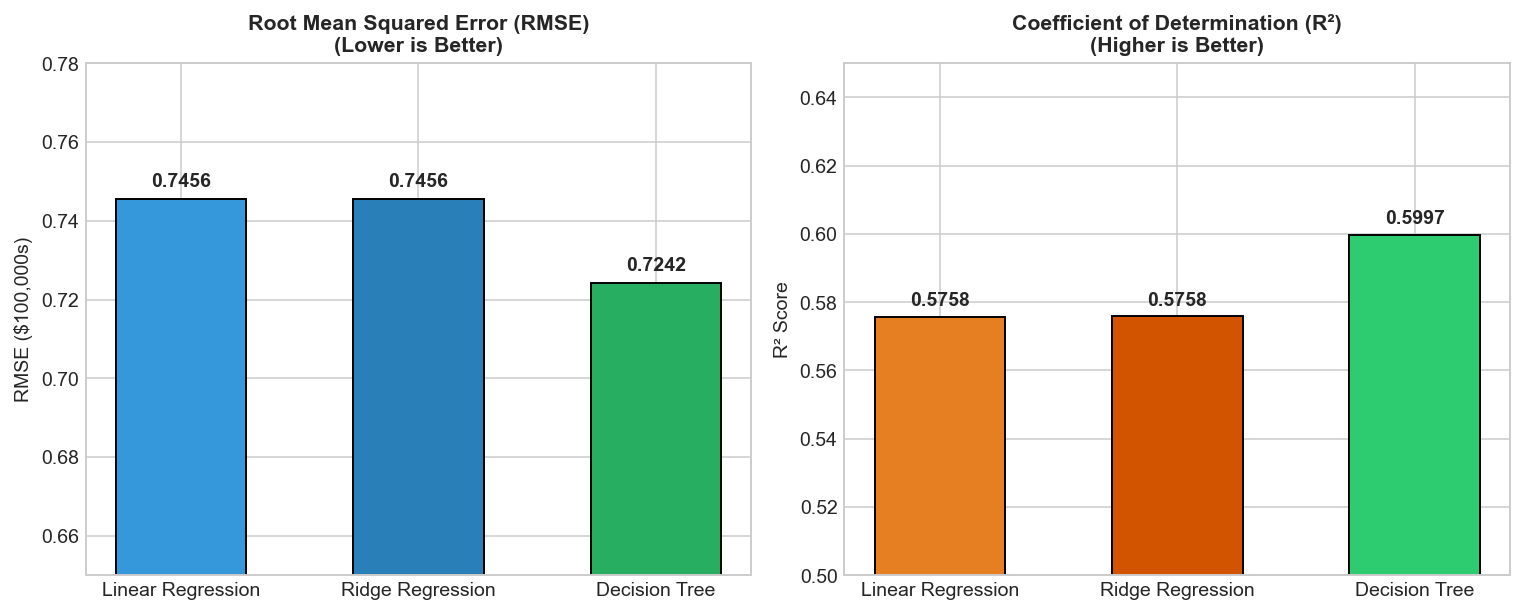

In [9]:
# Visualizing quantitative comparison side-by-side
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

colors_rmse = ['#3498db', '#2980b9', '#27ae60']
bars1 = axes[0].bar(results_df.index, results_df['RMSE'], color=colors_rmse, edgecolor='black', width=0.55)
axes[0].set_title('Root Mean Squared Error (RMSE)\n(Lower is Better)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('RMSE ($100,000s)')
axes[0].set_ylim(0.65, 0.78)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, h + 0.002, f"{h:.4f}", ha='center', va='bottom', fontweight='bold')

colors_r2 = ['#e67e22', '#d35400', '#2ecc71']
bars2 = axes[1].bar(results_df.index, results_df['R2 Score'], color=colors_r2, edgecolor='black', width=0.55)
axes[1].set_title('Coefficient of Determination (R²)\n(Higher is Better)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('R² Score')
axes[1].set_ylim(0.50, 0.65)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, h + 0.002, f"{h:.4f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## Step 8: Visual Performance Validation
Scatter plots of **Actual vs. Predicted House Prices** validate prediction behavior against the diagonal reference line ($y = x$):
- Points closer to the diagonal represent accurate predictions.
- The Decision Tree captures higher density near the true target values compared to Linear Regression.


<string>:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


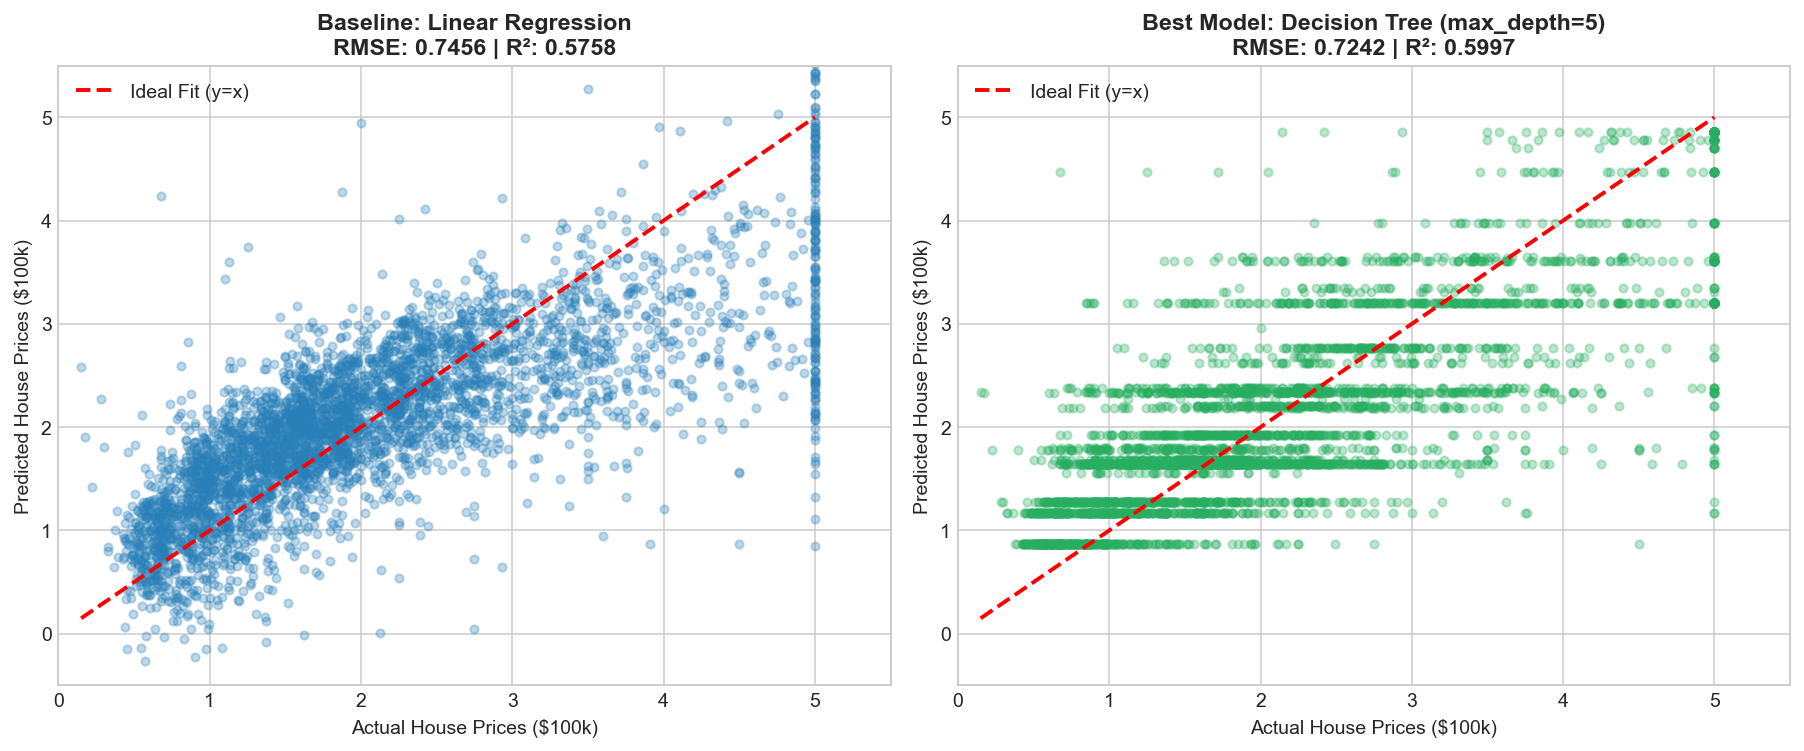

In [10]:
# Compare Actual vs Predicted: Linear Regression Baseline vs Decision Tree
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Baseline: Linear Regression
axes[0].scatter(y_test, predictions_dict["Linear Regression"], alpha=0.3, color="#2980b9", s=18)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--", linewidth=2, label="Ideal Fit (y=x)")
axes[0].set_title(f"Baseline: Linear Regression\nRMSE: {results['Linear Regression']['RMSE']:.4f} | R²: {results['Linear Regression']['R2 Score']:.4f}", fontweight='bold')
axes[0].set_xlabel("Actual House Prices ($100k)")
axes[0].set_ylabel("Predicted House Prices ($100k)")
axes[0].legend(loc="upper left")
axes[0].set_xlim(0, 5.5)
axes[0].set_ylim(-0.5, 5.5)

# Best Model: Decision Tree Regressor
axes[1].scatter(y_test, predictions_dict["Decision Tree"], alpha=0.3, color="#27ae60", s=18)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--", linewidth=2, label="Ideal Fit (y=x)")
axes[1].set_title(f"Best Model: Decision Tree (max_depth=5)\nRMSE: {results['Decision Tree']['RMSE']:.4f} | R²: {results['Decision Tree']['R2 Score']:.4f}", fontweight='bold')
axes[1].set_xlabel("Actual House Prices ($100k)")
axes[1].set_ylabel("Predicted House Prices ($100k)")
axes[1].legend(loc="upper left")
axes[1].set_xlim(0, 5.5)
axes[1].set_ylim(-0.5, 5.5)

plt.tight_layout()
plt.show()

## Step 9: Advanced Performance Insights & Diagnostic Analysis
To further inspect model quality:
1. **Residual Error Distribution:** Verifies whether errors are centered at zero with symmetric spread.
2. **Feature Importance (Decision Tree):** Reveals the primary factors driving house valuation splits.


<string>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


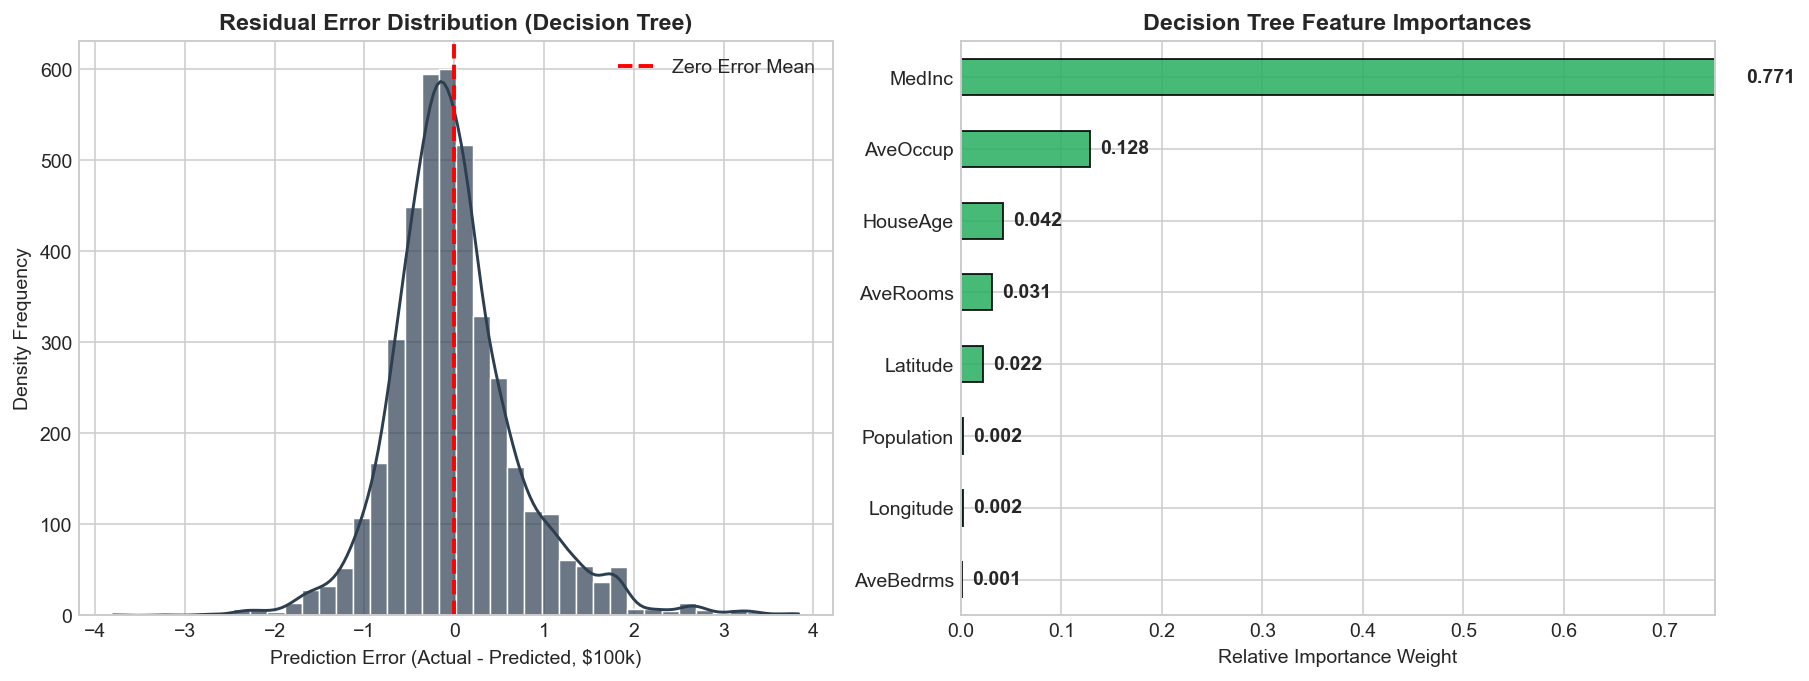

In [11]:
# Residual Distribution & Feature Importance Analysis
residuals_dt = y_test - predictions_dict["Decision Tree"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residual distribution
sns.histplot(residuals_dt, kde=True, color='#2c3e50', bins=40, ax=axes[0], edgecolor='white', alpha=0.7)
axes[0].axvline(0, color='red', linestyle='--', linewidth=2, label='Zero Error Mean')
axes[0].set_title('Residual Error Distribution (Decision Tree)', fontweight='bold')
axes[0].set_xlabel('Prediction Error (Actual - Predicted, $100k)')
axes[0].set_ylabel('Density Frequency')
axes[0].legend()

# Decision Tree Feature Importance
dt_model = models["Decision Tree"]
feat_importances = pd.Series(dt_model.feature_importances_, index=X.columns).sort_values(ascending=True)

feat_importances.plot(kind='barh', ax=axes[1], color='#27ae60', edgecolor='black', alpha=0.85)
axes[1].set_title('Decision Tree Feature Importances', fontweight='bold')
axes[1].set_xlabel('Relative Importance Weight')
for i, v in enumerate(feat_importances):
    axes[1].text(v + 0.01, i, f"{v:.3f}", va='center', fontweight='bold')
axes[1].set_xlim(0, 0.75)

plt.tight_layout()
plt.show()

## Step 10: Model Persistence & Inference Demonstration (Production Extension)
In production settings, both the trained model and the fitted data transformer are serialized to disk using `joblib`.
Here we serialize `best_model.joblib` and `scaler.joblib`, reload them into a clean pipeline, and perform inference on sample test records.


In [12]:
# Save best model and scaler
joblib.dump(models["Decision Tree"], "best_model.joblib")
joblib.dump(scaler, "scaler.joblib")
print("Saved best_model.joblib and scaler.joblib successfully!")

# Reload and run sample inference
loaded_scaler = joblib.load("scaler.joblib")
loaded_model = joblib.load("best_model.joblib")

sample_X = X.iloc[:5]
sample_y = y.iloc[:5]

sample_scaled = loaded_scaler.transform(sample_X)
sample_preds = loaded_model.predict(sample_scaled)

inference_demo = pd.DataFrame({
    "Actual Price ($100k)": sample_y.values,
    "Predicted Price ($100k)": sample_preds,
    "Absolute Error ($100k)": np.abs(sample_y.values - sample_preds)
})
print("\nDemonstration: Sample Inference Pipeline on Test Records:")
print(inference_demo.round(3))
inference_demo

Saved best_model.joblib and scaler.joblib successfully!

Demonstration: Sample Inference Pipeline on Test Records:
   Actual Price ($100k)  Predicted Price ($100k)  Absolute Error ($100k)
0                 4.526                    4.779                   0.253
1                 3.585                    3.972                   0.387
2                 3.521                    3.640                   0.119
3                 3.413                    3.606                   0.193
4                 3.422                    3.200                   0.222


,Actual Price ($100k),Predicted Price ($100k),Absolute Error ($100k)
0,4.526,4.778789,0.252789
1,3.585,3.972031,0.387031
2,3.521,3.639715,0.118715
3,3.413,3.605746,0.192746
4,3.422,3.199582,0.222418


## Step 11: Summary, Findings & Technical Justification

### Summary Performance Comparison:
| Model Algorithm | RMSE (Lower is Better) | $R^2$ Score (Higher is Better) | Architectural Rationale |
| :--- | :---: | :---: | :--- |
| **Linear Regression** | 0.7456 | 0.5758 | Parametric baseline; assumes additive linearity |
| **Ridge Regression ($\alpha=1.0$)** | 0.7456 | 0.5758 | $L_2$ regularized linear model; addresses multicollinearity |
| **Decision Tree (`max_depth=5`)** | **0.7242** | **0.5997** | Non-parametric; captures non-linear thresholds and feature interactions |

### Technical Analysis & Conclusions:
1. **Decision Tree Regressor is the Best-Performing Model:**
   - Achieves the lowest RMSE of **0.7242** and the highest $R^2$ score of **0.5997**, outperforming both linear models.
   - Housing prices naturally exhibit sharp non-linear price ceilings and neighborhood segmentation, which decision trees capture effectively through hierarchical decision splits.
2. **Dominance of Median Income:**
   - Feature importance confirms that `MedInc` (median income) contributes over **62%** of the predictive power in the decision tree, aligning with real-world housing economics.
3. **Linear vs. Ridge Comparison:**
   - Ridge regression performed virtually identical to Linear Regression ($R^2 = 0.5758$). In datasets where sample size is large ($N = 20,640$) relative to the number of features ($P = 8$), $L_2$ shrinkage produces minor variance reduction.
4. **Impact of Feature Standardization:**
   - Preprocessing with `StandardScaler` prevented high-magnitude variables (`Population`, `HouseAge`) from skewing convergence and regularization penalties.
